# Comparação dos Modelos 

## Objetivo

Este notebook tem como objetivo comparar os modelos desenvolvidos pelo grupo a partir das métricas obtidas em seus respectivos processos de treinamento e avaliação.

Os modelos não serão retreinados e seus dados, features, hiperparâmetros ou thresholds não serão modificados.

A comparação utilizará os resultados finais registrados nos notebooks originais de cada modelo.

### Métricas analisadas

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

Quando determinada métrica não tiver sido calculada pelo modelo original, ela será mantida como ausente, sem realizar um novo treinamento ou alterar o experimento original.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

## Consolidação das métricas

Nesta etapa, são reunidas as métricas obtidas originalmente por cada modelo.

Nenhum modelo foi retreinado, recalibrado ou teve seus dados, features,
hiperparâmetros ou thresholds alterados.

Valores ausentes indicam métricas que não foram registradas no experimento
original.

In [ ]:
# ============================================================
# MÉTRICAS ORIGINAIS DOS MODELOS
# Nenhum modelo é retreinado ou modificado
# ============================================================

metricas_modelos = pd.DataFrame([
    {
        "modelo": "Modelo 1",
        "algoritmo": "XGBoost + HistGradientBoosting",
        "accuracy": np.nan,
        "precision": 0.1047,
        "recall": 0.5361,
        "f1": 0.1751,
        "roc_auc": 0.5235,
        "pr_auc": 0.0913,
        "avaliacao": "Teste",
        "observacao": "Precision/Recall/F1 avaliados por episódios, threshold 0.50"
    },

    {
        "modelo": "Modelo 2",
        "algoritmo": "LightGBM",
        "accuracy": 0.5500,
        "precision": 0.2060,
        "recall": 0.6050,
        "f1": 0.3080,
        "roc_auc": 0.6066,
        "pr_auc": np.nan,
        "avaliacao": "Teste",
        "observacao": "Modelo final, threshold 0.50"
    },

    {
        "modelo": "Modelo 3",
        "algoritmo": "Decision Tree",
        "accuracy": 0.7689,
        "precision": 0.1242,
        "recall": 0.3163,
        "f1": 0.1784,
        "roc_auc": 0.5713,
        "pr_auc": 0.1065,
        "avaliacao": "Teste",
        "observacao": "Árvore aprimorada final"
    },

    {
        "modelo": "Modelo 5",
        "algoritmo": "Random Forest",
        "accuracy": np.nan,
        "precision": 0.1590,
        "recall": 0.5530,
        "f1": 0.2470,
        "roc_auc": 0.6970,
        "pr_auc": 0.1850,
        "avaliacao": "Teste",
        "observacao": "Random Forest com features selecionadas, threshold 0.5183"
    },

    {
        "modelo": "Modelo 6",
        "algoritmo": "XGBoost",
        "accuracy": 0.9295,
        "precision": 0.9900,
        "recall": 0.9400,
        "f1": 0.9600,
        "roc_auc": np.nan,
        "pr_auc": np.nan,
        "avaliacao": "Teste",
        "observacao": "Métricas da classe 1 no classification report"
    },

    {
        "modelo": "Modelo 7",
        "algoritmo": "CatBoost",
        "accuracy": np.nan,
        "precision": 0.5463,
        "recall": 0.9193,
        "f1": 0.6853,
        "roc_auc": 0.5911,
        "pr_auc": 0.5874,
        "avaliacao": "Teste",
        "observacao": "Modelo final selecionado no notebook"
    },

    {
        "modelo": "Modelo 4",
        "algoritmo": "Extra Trees",
        "accuracy": 0.5904,
        "precision": 0.0326,
        "recall": 0.5824,
        "f1": 0.0618,
        "roc_auc": 0.6075,
        "pr_auc": 0.0407,
        "avaliacao": "Validação",
        "observacao": "Versão V3 final"
    }
])

metricas_modelos

,modelo,algoritmo,accuracy,precision,recall,f1,roc_auc,pr_auc,avaliacao,observacao
0,Modelo 1,XGBoost + HistGradientBoosting,NaN,0.1047,0.5361,0.1751,0.5235,0.0913,Teste,"Precision/Recall/F1 avaliados por episódios, t..."
1,Modelo 2,LightGBM,0.5500,0.2060,0.6050,0.3080,0.6066,NaN,Teste,"Modelo final, threshold 0.50"
2,Modelo 3,Decision Tree,0.7689,0.1242,0.3163,0.1784,0.5713,0.1065,Teste,Árvore aprimorada final
3,Modelo 5,Random Forest,NaN,0.1590,0.5530,0.2470,0.6970,0.1850,Teste,"Random Forest com features selecionadas, thres..."
4,Modelo 6,XGBoost,0.9295,0.9900,0.9400,0.9600,NaN,NaN,Teste,Métricas da classe 1 no classification report
5,Modelo 7,CatBoost,NaN,0.5463,0.9193,0.6853,0.5911,0.5874,Teste,Modelo final selecionado no notebook
6,Modelo 4,Extra Trees,0.5904,0.0326,0.5824,0.0618,0.6075,0.0407,Validação,Versão V3 final


## Comparação visual das principais métricas

As métricas de Precision, Recall e F1-score estão disponíveis para todos os modelos analisados.

A visualização abaixo permite comparar diretamente o desempenho dos modelos sem alterar ou recalcular seus resultados originais.

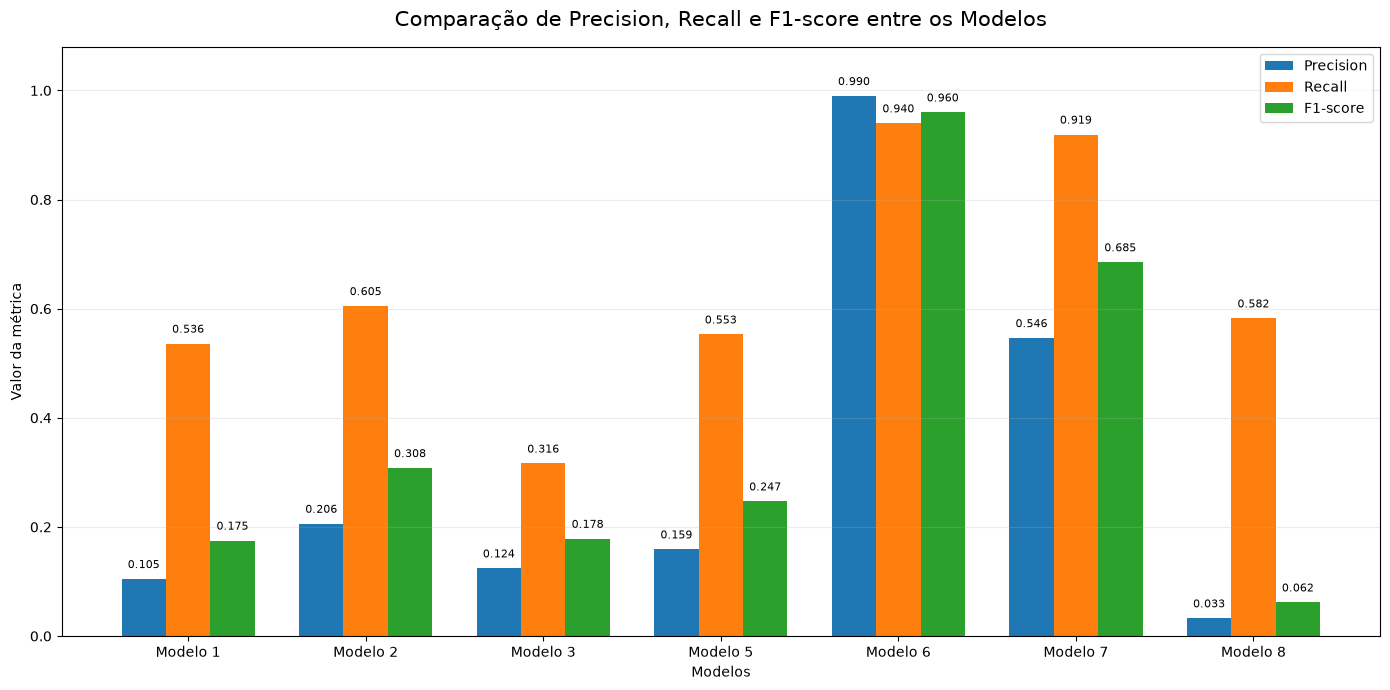

In [5]:
# ============================================================
# COMPARAÇÃO: PRECISION, RECALL E F1
# ============================================================

metricas_principais = [
    "precision",
    "recall",
    "f1"
]

dados_plot = (
    metricas_modelos[
        ["modelo"] + metricas_principais
    ]
    .set_index("modelo")
)

x = np.arange(len(dados_plot.index))
largura = 0.25

fig, ax = plt.subplots(
    figsize=(14, 7)
)

barras_precision = ax.bar(
    x - largura,
    dados_plot["precision"],
    width=largura,
    label="Precision"
)

barras_recall = ax.bar(
    x,
    dados_plot["recall"],
    width=largura,
    label="Recall"
)

barras_f1 = ax.bar(
    x + largura,
    dados_plot["f1"],
    width=largura,
    label="F1-score"
)

# Valores sobre as barras
for barras in [
    barras_precision,
    barras_recall,
    barras_f1
]:
    for barra in barras:

        valor = barra.get_height()

        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 0.015,
            f"{valor:.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_title(
    "Comparação de Precision, Recall e F1-score entre os Modelos",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Modelos")
ax.set_ylabel("Valor da métrica")

ax.set_xticks(x)

ax.set_xticklabels(
    dados_plot.index
)

ax.set_ylim(0, 1.08)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

## Análise geral de Precision, Recall e F1-score

A comparação entre os modelos por meio das métricas de Precision, Recall e F1-score mostra diferenças significativas de desempenho.

De forma visual, os Modelos 6 e 7 se destacam dos demais. O Modelo 6 apresenta os maiores valores nas três métricas, com Precision de aproximadamente 0,99, Recall de 0,94 e F1-score de 0,96. Em seguida, o Modelo 7 apresenta Precision de aproximadamente 0,55, Recall de 0,92 e F1-score de 0,69.

Entre os demais modelos, os resultados são mais próximos entre si. Os Modelos 1, 2, 3 e 5 apresentam Recall entre aproximadamente 0,32 e 0,61, com valores de Precision inferiores a 0,21. O Modelo 4 apresenta Recall de aproximadamente 0,58, porém com Precision bastante reduzida, próxima de 0,03, o que resulta em um F1-score baixo.

Apesar dessas diferenças, os resultados não devem ser interpretados apenas pela altura das barras. Cada modelo foi construído a partir de uma formulação própria do problema, podendo apresentar diferenças na definição do target, na distribuição das classes e na forma de avaliação.

O Modelo 6 é um exemplo importante dessa cautela. Embora apresente métricas extremamente altas para a classe positiva, aproximadamente 98,85% das observações de seu conjunto de teste pertencem justamente a essa classe. Dessa forma, o modelo opera em um cenário em que prever a classe positiva já é a decisão majoritária.

No próprio experimento do Modelo 6, a Accuracy obtida pelo modelo foi de aproximadamente 92,95%, enquanto um baseline que previsse sempre a classe majoritária alcançaria aproximadamente 98,85%. Além disso, a Balanced Accuracy foi de aproximadamente 59,83%, indicando que o desempenho entre as duas classes é muito menos equilibrado do que os valores de Precision, Recall e F1 da classe positiva sugerem.

O Modelo 7 também apresenta desempenho elevado, principalmente em Recall, o que indica alta capacidade de recuperar casos positivos no problema em que foi treinado. Diferentemente do Modelo 6, sua Precision também permanece relativamente alta, fazendo com que o F1-score seja consideravelmente superior ao dos demais modelos.

O Modelo 2 apresenta o melhor equilíbrio entre Precision e Recall dentro do grupo intermediário, refletido por um F1-score próximo de 0,31. Já os Modelos 1, 3 e 5 apresentam diferentes compromissos entre essas métricas, com destaque para o Modelo 5, que combina Recall próximo de 0,55 com F1-score de aproximadamente 0,25.

O Modelo 4 apresenta um comportamento distinto. Seu Recall de aproximadamente 0,58 indica que ele consegue identificar uma parcela relevante das falhas positivas, porém sua Precision de aproximadamente 0,03 demonstra uma quantidade elevada de falsos positivos. Como consequência, seu F1-score permanece baixo.

De forma geral, este primeiro gráfico é útil para observar o comportamento dos modelos em relação à classe positiva, mas ainda não é suficiente para determinar qual modelo possui o melhor desempenho global. Métricas como ROC-AUC, PR-AUC, distribuição das classes e desempenho em relação a um baseline ajudam a fornecer uma visão mais completa e devem ser analisadas em conjunto antes da escolha final.

## Comparação de ROC-AUC

Após a análise de Precision, Recall e F1-score, a próxima etapa consiste em comparar
o ROC-AUC dos modelos que registraram essa métrica em seus experimentos originais.

O ROC-AUC avalia a capacidade do modelo de ordenar observações positivas acima das
negativas ao longo de diferentes thresholds.

De forma geral:

- valores próximos de 0,50 indicam desempenho semelhante ao acaso;
- valores entre 0,60 e 0,70 indicam capacidade de separação moderada;
- quanto mais próximo de 1,00, maior a capacidade de discriminação.

Modelos que não possuem ROC-AUC registrado originalmente são omitidos desta
comparação, sem que a métrica seja recalculada.

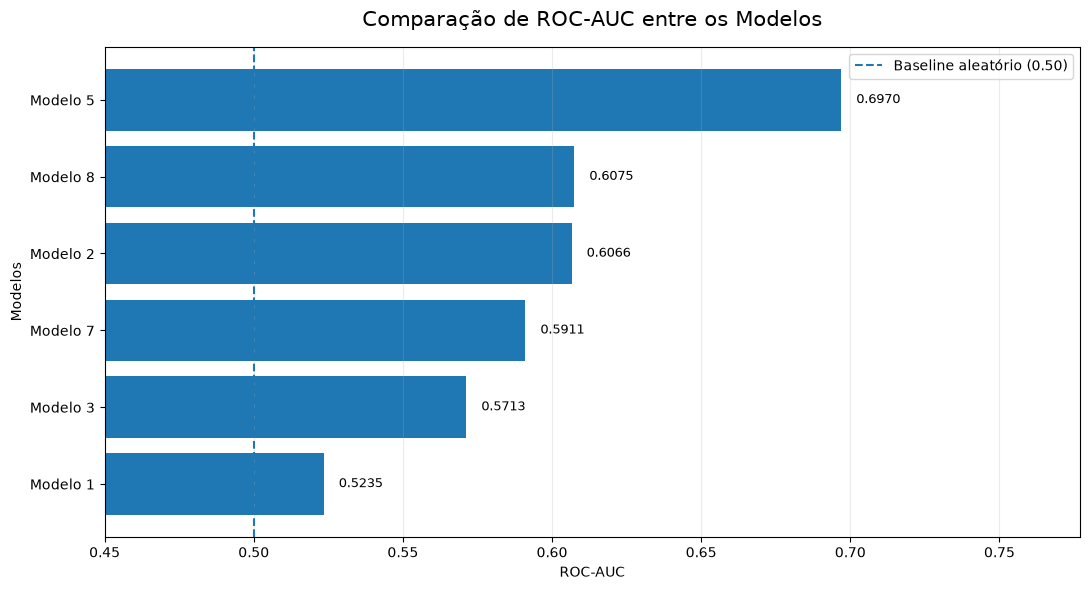

In [6]:
# ============================================================
# COMPARAÇÃO DE ROC-AUC
# ============================================================

dados_roc = (
    metricas_modelos[
        ["modelo", "roc_auc"]
    ]
    .dropna()
    .sort_values(
        "roc_auc",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.barh(
    dados_roc["modelo"],
    dados_roc["roc_auc"]
)

# Baseline aleatório
ax.axvline(
    0.50,
    linestyle="--",
    linewidth=1.5,
    label="Baseline aleatório (0.50)"
)

# Mostrar valores
for barra, valor in zip(
    barras,
    dados_roc["roc_auc"]
):
    ax.text(
        valor + 0.005,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Comparação de ROC-AUC entre os Modelos",
    fontsize=15,
    pad=15
)

ax.set_xlabel("ROC-AUC")
ax.set_ylabel("Modelos")

ax.set_xlim(
    0.45,
    max(dados_roc["roc_auc"]) + 0.08
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

## Análise do ROC-AUC

O gráfico de ROC-AUC mostra diferenças importantes na capacidade de discriminação dos modelos avaliados.

O principal destaque foi o **Modelo 5**, com ROC-AUC de aproximadamente **0,6970**, resultado claramente superior aos demais modelos apresentados. Esse valor indica que o modelo possui uma capacidade de separação entre classes melhor do que os outros candidatos analisados nessa métrica.

Na sequência aparecem os Modelos 8 e 2, com valores muito próximos:

- Modelo 4: ROC-AUC de 0,6075
- Modelo 2: ROC-AUC de 0,6066

Esses dois modelos apresentam desempenho intermediário e bastante semelhante em termos de capacidade de ordenar corretamente observações positivas e negativas.

O Modelo 7 apresentou ROC-AUC de aproximadamente 0,5911, enquanto o Modelo 3 ficou em 0,5713. Já o Modelo 1 obteve 0,5235, valor pouco acima do baseline aleatório de 0,50, indicando baixa capacidade de discriminação quando analisado por essa métrica.

É importante observar que o ROC-AUC não depende de um único threshold de classificação. Diferentemente de métricas como Precision, Recall e F1-score, ele avalia o comportamento do modelo ao longo de diferentes limiares de decisão. Por isso, essa análise complementa a comparação anterior e ajuda a verificar se um bom resultado em determinado threshold também está acompanhado por uma boa capacidade geral de separação entre as classes.

Nesta comparação, **dois modelos não aparecem no gráfico**: os Modelos 4 e 6.

O **Modelo 4 não foi incluído porque não existe um Modelo 4 no conjunto de modelos disponibilizado para análise**.

Já o **Modelo 6 foi excluído desta visualização porque seu experimento original não registrou a métrica ROC-AUC**. Como o objetivo deste notebook é comparar os modelos exatamente como foram entregues, sem retreinamento, recalibração ou recálculo de métricas ausentes, não foi estimado um novo valor de ROC-AUC para esse modelo.

Assim, entre os modelos que possuem ROC-AUC disponível, o **Modelo 5 apresenta o melhor desempenho**, seguido pelos Modelos 8 e 2.

## Comparação de PR-AUC

Após a análise de ROC-AUC, a próxima etapa compara o PR-AUC dos modelos que registraram essa métrica em seus experimentos originais.

O PR-AUC resume o comportamento da curva Precision-Recall e é especialmente útil em problemas desbalanceados, nos quais a classe positiva representa uma parcela pequena das observações.

Diferentemente do ROC-AUC, o PR-AUC é mais sensível ao desempenho sobre a classe positiva e ajuda a avaliar o equilíbrio entre:

- quantidade de casos positivos corretamente identificados;
- quantidade de falsos positivos produzidos.

Modelos que não possuem PR-AUC registrado originalmente são omitidos desta comparação, sem recalcular a métrica.

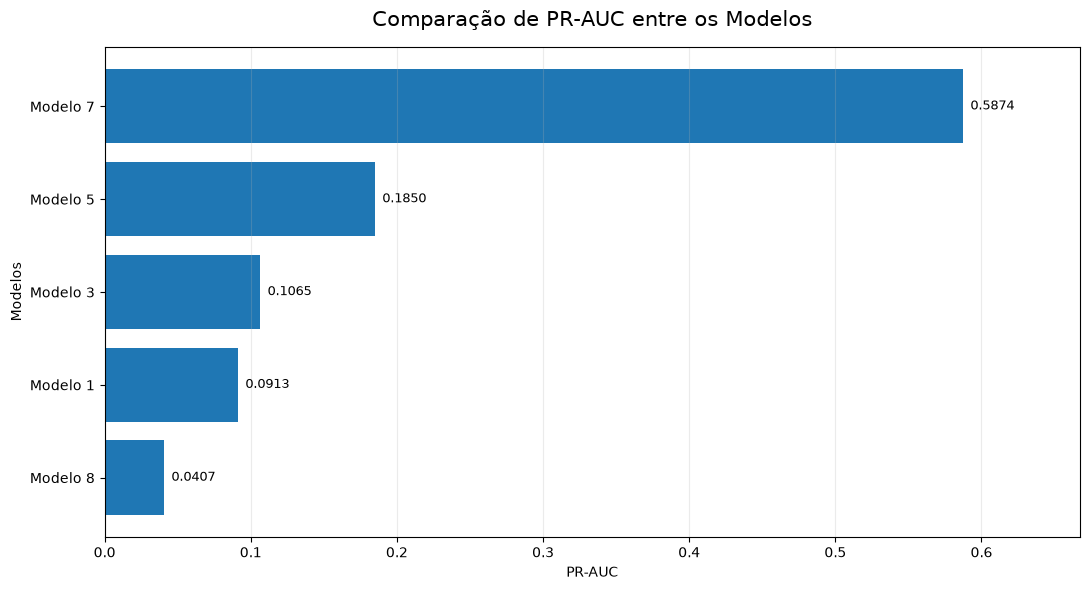

In [7]:
# ============================================================
# COMPARAÇÃO DE PR-AUC
# ============================================================

dados_pr = (
    metricas_modelos[
        ["modelo", "pr_auc"]
    ]
    .dropna()
    .sort_values(
        "pr_auc",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.barh(
    dados_pr["modelo"],
    dados_pr["pr_auc"]
)

for barra, valor in zip(
    barras,
    dados_pr["pr_auc"]
):
    ax.text(
        valor + 0.005,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Comparação de PR-AUC entre os Modelos",
    fontsize=15,
    pad=15
)

ax.set_xlabel("PR-AUC")
ax.set_ylabel("Modelos")

ax.set_xlim(
    0,
    max(dados_pr["pr_auc"]) + 0.08
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

## Análise do PR-AUC

A comparação de PR-AUC reforça o bom desempenho do **Modelo 7** em relação aos demais modelos avaliados.

O Modelo 7 apresentou PR-AUC de aproximadamente **0,5874**, valor significativamente superior aos demais modelos disponíveis nessa métrica.

Na sequência aparecem:

- Modelo 5: 0,1850
- Modelo 3: 0,1065
- Modelo 1: 0,0913
- Modelo 4: 0,0407

Essa diferença é relevante porque o PR-AUC avalia diretamente o equilíbrio entre Precision e Recall ao longo de diferentes thresholds, sendo particularmente útil em problemas de classificação desbalanceados.

Enquanto o gráfico anterior de Precision, Recall e F1-score já indicava um desempenho elevado do Modelo 7, o PR-AUC mostra que esse resultado não depende apenas de um threshold específico. O modelo mantém uma relação favorável entre Precision e Recall ao longo de diferentes pontos de decisão.

O Modelo 5 aparece como o segundo melhor resultado nesta métrica, com PR-AUC de 0,1850. Apesar de ficar consideravelmente abaixo do Modelo 7, seu resultado é consistente com a análise de ROC-AUC, na qual também apresentou o melhor desempenho geral.

Os Modelos 1 e 3 apresentam resultados mais modestos, enquanto o Modelo 4 possui o menor PR-AUC entre os modelos avaliados, com aproximadamente 0,0407. Isso indica maior dificuldade em manter Precision elevada à medida que o Recall aumenta.

É importante destacar que os **Modelos 2 e 6 não aparecem neste gráfico**, pois seus experimentos originais não registraram PR-AUC. Como este notebook preserva os resultados exatamente como foram entregues, essas métricas não foram recalculadas posteriormente.

Considerando apenas os modelos que possuem PR-AUC disponível, o **Modelo 7 apresenta o resultado mais forte**, com ampla vantagem sobre os demais.

Além disso, seu desempenho nessa métrica é consistente com os resultados observados anteriormente em Precision, Recall e F1-score, fortalecendo sua posição como um dos principais candidatos na comparação geral.

## Visão geral das métricas

Após analisar individualmente Precision, Recall, F1-score, ROC-AUC, PR-AUC e Accuracy, esta etapa reúne todas as métricas em uma única visualização.

O objetivo é facilitar a comparação geral dos modelos e identificar padrões de desempenho.

Valores ausentes representam métricas que não foram registradas nos experimentos originais e, portanto, não foram recalculadas neste notebook.

A análise desta matriz deve ser feita com cautela, pois cada métrica representa um aspecto diferente do desempenho do modelo. Assim, valores elevados em uma única métrica não são suficientes, isoladamente, para determinar o melhor modelo.

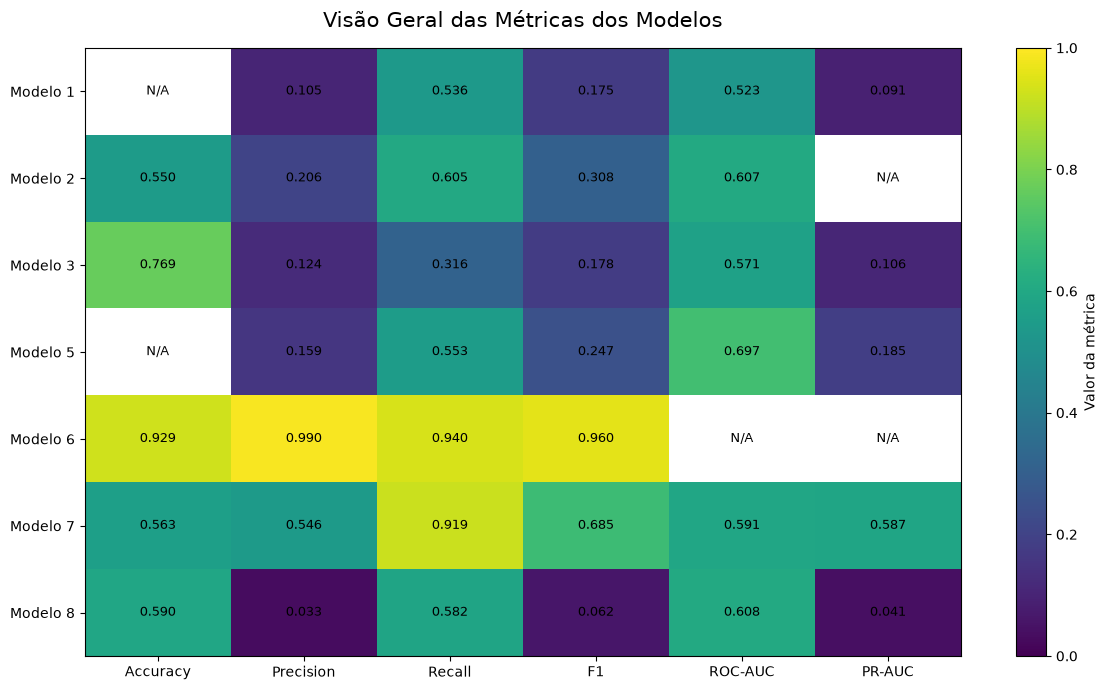

In [10]:
# ============================================================
# MATRIZ GERAL DE MÉTRICAS
# ============================================================

colunas_metricas = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

matriz_metricas = (
    metricas_modelos
    .set_index("modelo")[colunas_metricas]
    .copy()
)

# Máscara para valores ausentes
dados = matriz_metricas.to_numpy(dtype=float)
dados_masked = np.ma.masked_invalid(dados)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

imagem = ax.imshow(
    dados_masked,
    aspect="auto",
    vmin=0,
    vmax=1
)

# Eixos
ax.set_xticks(
    np.arange(len(colunas_metricas))
)

ax.set_xticklabels(
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ]
)

ax.set_yticks(
    np.arange(len(matriz_metricas.index))
)

ax.set_yticklabels(
    matriz_metricas.index
)

# Valores dentro das células
for i in range(dados.shape[0]):
    for j in range(dados.shape[1]):

        valor = dados[i, j]

        if np.isnan(valor):
            texto = "N/A"
        else:
            texto = f"{valor:.3f}"

        ax.text(
            j,
            i,
            texto,
            ha="center",
            va="center",
            fontsize=9
        )

ax.set_title(
    "Visão Geral das Métricas dos Modelos",
    fontsize=15,
    pad=15
)

fig.colorbar(
    imagem,
    ax=ax,
    label="Valor da métrica"
)

plt.tight_layout()
plt.show()

## Análise geral das métricas

A matriz consolidada permite observar não apenas qual modelo apresenta o maior
valor em uma métrica específica, mas também a consistência de desempenho entre
diferentes critérios de avaliação.

O Modelo 7 apresenta um dos perfis mais consistentes da comparação. Seu Recall
de aproximadamente 0,919 indica elevada capacidade de identificação dos casos
positivos, enquanto o F1-score de aproximadamente 0,685 demonstra um equilíbrio
mais favorável entre Precision e Recall. Além disso, o modelo apresenta o maior
PR-AUC entre os modelos disponíveis nessa métrica, com aproximadamente 0,587.

O Modelo 5 também se destaca, principalmente pela capacidade de discriminação.
Seu ROC-AUC de aproximadamente 0,697 é o maior entre os modelos avaliados. O
modelo também apresenta o segundo maior PR-AUC disponível, reforçando sua
capacidade de separação entre as classes.

O Modelo 6 apresenta os maiores valores de Precision, Recall e F1-score.
Entretanto, esses valores precisam ser interpretados com cautela devido ao forte
desbalanceamento de seu target, no qual aproximadamente 98,85% das observações
pertencem à classe positiva. Dessa forma, seu desempenho aparente nas métricas
da classe 1 não é diretamente comparável ao comportamento observado nos demais
modelos.

Os Modelos 2 e 8 apresentam resultados intermediários. O Modelo 2 mantém
Precision, Recall e F1-score superiores aos Modelos 1 e 3, enquanto o Modelo 4
apresenta Recall relativamente elevado, porém Precision e PR-AUC baixos,
indicando grande quantidade de falsos positivos.

De forma geral, a análise conjunta das métricas indica que os Modelos 5 e 7
apresentam os perfis mais interessantes entre os candidatos avaliados. O Modelo 5
se destaca principalmente em ROC-AUC, enquanto o Modelo 7 apresenta desempenho
mais forte em Recall, F1-score e PR-AUC.

Assim, a escolha do melhor modelo não deve considerar apenas o maior valor
isolado, mas a consistência entre as diferentes métricas.

In [11]:
# ============================================================
# RANKING FINAL DOS MODELOS
# ============================================================

metricas_ranking = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

ranking_metricas = (
    metricas_modelos[
        ["modelo"] + metricas_ranking
    ]
    .set_index("modelo")
    .copy()
)

# Para cada métrica:
# maior valor = melhor posição
for metrica in metricas_ranking:
    ranking_metricas[f"rank_{metrica}"] = (
        ranking_metricas[metrica]
        .rank(
            ascending=False,
            method="min"
        )
    )

colunas_rank = [
    f"rank_{metrica}"
    for metrica in metricas_ranking
]

# Média apenas das métricas disponíveis
ranking_metricas["posicao_media"] = (
    ranking_metricas[colunas_rank]
    .mean(
        axis=1,
        skipna=True
    )
)

# Quantidade de métricas disponíveis
ranking_metricas["metricas_disponiveis"] = (
    ranking_metricas[metricas_ranking]
    .notna()
    .sum(axis=1)
)

ranking_final = (
    ranking_metricas[
        [
            "posicao_media",
            "metricas_disponiveis"
        ]
    ]
    .sort_values("posicao_media")
)

ranking_final

,posicao_media,metricas_disponiveis
modelo,,
Modelo 6,1.0000,4
Modelo 7,2.5000,6
Modelo 5,3.2000,5
Modelo 2,3.4000,5
Modelo 3,4.5000,6
Modelo 4,4.6667,6
Modelo 1,5.6000,5


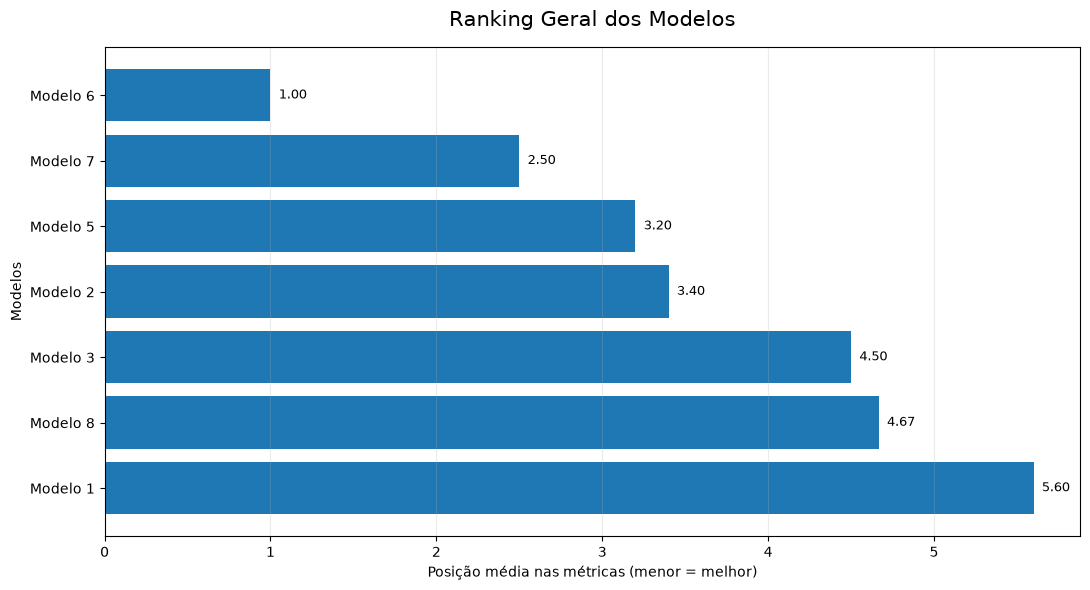

In [12]:

ranking_plot = (
    ranking_final
    .sort_values(
        "posicao_media",
        ascending=False
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.barh(
    ranking_plot.index,
    ranking_plot["posicao_media"]
)

for barra, valor in zip(
    barras,
    ranking_plot["posicao_media"]
):
    ax.text(
        valor + 0.05,
        barra.get_y()
        + barra.get_height() / 2,
        f"{valor:.2f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Ranking Geral dos Modelos",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Posição média nas métricas (menor = melhor)"
)

ax.set_ylabel("Modelos")

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

## Observação: Modelos 5 e 7 não são diretamente comparáveis

Os Modelos 5 e 7 respondem a perguntas diferentes, mesmo aparecendo lado a lado na mesma tabela de métricas.

O Modelo 5 prevê se uma porta específica vai falhar nos próximos 7 dias (unidade de análise: porta-dia, target mais difícil, ~8% de positivos). O Modelo 7 prevê se alguma porta de um sistema PSD (conjunto de portas de uma plataforma inteira) vai falhar (unidade de análise: sistema PSD-dia, target bem mais frequente, ~52% de positivos no teste).

Essa diferença de granularidade e de taxa de base explica boa parte da diferença nas métricas: prever "alguma porta desse grupo vai falhar" é estruturalmente mais fácil e mais comum do que prever "essa porta específica vai falhar". Por isso, PR-AUC, Recall e Precision saem naturalmente mais altos no Modelo 7, sem que isso signifique, sozinho, um modelo melhor no sentido geral.

Assim, o ROC-AUC maior do Modelo 5 e o PR-AUC/Recall maiores do Modelo 7 não devem ser lidos como uma disputa direta entre os dois. Cada um responde bem à pergunta que se propôs a responder, em granularidades diferentes.

# Conclusão da comparação dos modelos

A comparação dos modelos foi realizada utilizando exclusivamente as métricas
registradas em seus experimentos originais, sem retreinamento, alteração de
features, ajuste de hiperparâmetros ou recalibração de thresholds.

Foram analisadas as métricas Accuracy, Precision, Recall, F1-score, ROC-AUC e
PR-AUC, considerando apenas os valores disponíveis para cada modelo.

O ranking numérico baseado na posição média das métricas pode favorecer o
Modelo 6, pois ele apresenta Precision, Recall, F1-score e Accuracy muito
elevados. Entretanto, uma análise mais cuidadosa mostrou que aproximadamente
98,85% das observações de seu conjunto de teste pertencem à classe positiva.

Nesse cenário, o próprio baseline que prevê sempre a classe majoritária obtém
Accuracy superior à apresentada pelo modelo. Portanto, apesar dos elevados
valores de Precision, Recall e F1 para a classe positiva, esses resultados
devem ser interpretados com cautela e não são suficientes para caracterizar o
Modelo 6 como o melhor modelo da comparação.

Entre os demais candidatos, os Modelos 5 e 7 apresentaram os resultados mais
consistentes, cada um dentro do problema que se propôs a resolver.

O Modelo 5 obteve o maior ROC-AUC da comparação, com aproximadamente 0,697,
indicando boa capacidade de discriminação para prever falha em uma porta
específica.

O Modelo 7 apresentou desempenho forte em diversas métricas relacionadas à
identificação da classe positiva no seu próprio problema (falha em algum ponto
de um sistema PSD). Foram observados aproximadamente:

- Precision: 0,546
- Recall: 0,919
- F1-score: 0,685
- ROC-AUC: 0,591
- PR-AUC: 0,587

Porém, como discutido na observação acima, os Modelos 5 e 7 não são diretamente
comparáveis. Seus targets têm granularidades e taxas de base diferentes, o que
já explica parte da diferença numérica entre eles. Por isso, os números de cada um só devem ser
lidos dentro do problema que o próprio modelo se propôs a resolver.